# run_experiments：刺激 × 条件 × 解析 の一括実行

処理本体は `cisim.py`、比較・解析は `analysis.py` にあります。このノートブックは**設定してループを回し、結果を見るだけ**です。

| 足したいもの | やること |
|---|---|
| 入力音 | セル2の `STIMULI` に1行追加 |
| 処理条件（λ, ε など） | セル1の設定を変更 |
| 数値指標 | `analysis.py` に関数を書いて `METRICS` に登録 |
| 図 | セル5以降で `plot_xxx` を呼ぶ |

出力先は `results/` です。`results/<刺激>/lam<λ>/*.wav` に聴き比べ用の音声、`results/metrics.csv` に全指標の表が保存されます。

**比較の考え方**：補償の残差は `vocoder`（拡散なし, G=I）を基準に見ます。`input` と直接比べると、ボコーダ自体の損失（TFSの欠落・雑音キャリア）が混ざってしまうためです。

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cisim as cs
import analysis as an
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")

## 1. 設定

In [2]:
cfg = cs.CIConfig(sr=16000, seed=0)   # パラメータは cisim.CIConfig を参照

LAMBDAS = [2.0, 5.0, 9.0]   # 電流拡散 λ [mm]
EPS     = 0.0               # 逆行列の正則化 ε（0 = セクション5-2と同じ）
MODE    = "noise"           # キャリア: 'noise' or 'tone'
RESULTS = "results"
print(cfg)

CIConfig(sr=16000, n_ch=22, fmin=188.0, fmax=7939.0, env_cut=400.0, bp_order=4, env_order=2, spacing=0.75, seed=0, causal=False)


## 2. 刺激（入力音）

`名前: 関数` の形で登録します。ファイルは `data/` などに置いてパスを書いてください（使わないものはコメントアウトのままで大丈夫です）。

In [3]:
sr = cfg.sr
STIMULI = {
    # --- テスト信号 ---
    "sweep":       lambda: cs.gen_sweep(sr, 100, 8000, dur=3.0),
    "sam_fm16":    lambda: cs.gen_sam(sr, fc=1000, fm=16),

    # --- 英語音声（同一文 EN0001） ---
    "en_m01":      lambda: cs.load_audio("data/speech_en/en_m01.wav", sr),
    "en_f01":      lambda: cs.load_audio("data/speech_en/en_f01.wav", sr),

    # --- 歌声（かたつむり, 最初の10秒） ---
    "song_m_low":  lambda: cs.load_audio("data/music_vocal/katatsumuri_m_low_jvs045.wav", sr, max_sec=10),
    "song_f_high": lambda: cs.load_audio("data/music_vocal/katatsumuri_f_high_jvs085.wav", sr, max_sec=10),

    # --- 楽器（歌声と同じ旋律, 最初の10秒） ---
    "piano_f_high": lambda: cs.gen_katatsumuri(sr, "f_high", "piano")[: sr * 10],
}
#STIMULI = {k: STIMULI[k] for k in ["sweep"]}   # 試し実行用。本番ではこの行を消す（または # を付ける）

# 比較する組（ref, test）。'input' は入力音そのもの
PAIRS = [
    ("input",   "vocoder"),     # ボコーダ自体の損失
    ("vocoder", "spread"),      # 電流拡散の影響
    ("vocoder", "comp_ideal"),  # 逆補償の残差（理想）
    ("vocoder", "comp_clip"),   # 逆補償の残差（電流≥0の制約あり）← 本題
    ("vocoder", "comp_nnls"),   # 逆補償の残差（NNLS）
]

## 3. 一括実行

In [4]:
rows = []
OUTS = {}   # 図を描くために結果を保持 {(刺激, λ): out}

for s_name, loader in STIMULI.items():
    x = loader()
    for lam in LAMBDAS:
        out = cs.run_conditions(x, cfg, lam, eps=EPS, mode=MODE)
        out["input"] = x
        OUTS[(s_name, lam)] = out
        cs.save_wavs(os.path.join(RESULTS, s_name, f"lam{lam:g}"), x, out, cfg.sr)

        for ref_k, test_k in PAIRS:
            row = {"stim": s_name, "lam": lam, "ref": ref_k, "test": test_k,
                   "neg_ratio": out["neg_ratio"]}
            row.update(an.compute_metrics(out[ref_k], out[test_k], cfg))
            # 包絡どうしの直接比較（vocoder基準のときだけ）
            if ref_k == "vocoder":
                row.update(an.env_error(out["env"], out["env_" + test_k]))
                row.update(an.env_contrast(out["env"], out["env_" + test_k]))
            rows.append(row)
    print("done:", s_name)

df = pd.DataFrame(rows)
os.makedirs(RESULTS, exist_ok=True)
df.to_csv(os.path.join(RESULTS, "metrics.csv"), index=False)
df.head()

done: sweep
done: sam_fm16


/Users/sekai/my_research/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


done: en_m01
done: en_f01
done: song_m_low
done: song_f_high
done: piano_f_high


,stim,lam,ref,test,neg_ratio,lag_ms,snr_db,lsd_db,ltas_rmse_db,coh_mean,env_corr_mean,env_corr_min,stoi,env_rel_err_mean,env_rel_err_max,env_rel_err_db,profile_corr,contrast_ratio
0,sweep,2.0,input,vocoder,0.722152,11.75,-3.312246,8.947301e+00,1.445666e+01,0.310193,0.875299,0.811950,0.636820,NaN,NaN,NaN,NaN,NaN
1,sweep,2.0,vocoder,spread,0.722152,0.00,1.436561,1.707763e+01,3.165369e+00,0.401168,0.699584,0.643421,0.488619,6.520809e-01,6.921940e-01,-1.848007,0.674829,0.293921
2,sweep,2.0,vocoder,comp_ideal,0.722152,0.00,128.469099,3.016761e-14,6.538438e-15,1.000000,1.000000,1.000000,1.000000,3.239597e-31,8.486766e-31,-120.000000,1.000000,1.000000
3,sweep,2.0,vocoder,comp_clip,0.722152,0.00,1.205400,1.705218e+01,2.691061e+00,0.365848,0.675009,0.482189,0.496801,1.381624e+01,1.665234e+01,11.389811,0.684694,0.296263
4,sweep,2.0,vocoder,comp_nnls,0.722152,0.00,1.598238,1.710794e+01,2.991216e+00,0.417041,0.710463,0.637551,0.498034,5.673063e-01,6.086170e-01,-2.445659,0.685390,0.296265


## 4. 表で見る

In [5]:
# 例: 補償後（comp_clip）の残差を 刺激 × λ で一覧
metric = "env_rel_err_db"   # 'snr_db', 'lsd_db', 'coh_mean', 'env_corr_mean' などに変更可
(df[df.test == "comp_clip"]
   .pivot_table(index="stim", columns="lam", values=metric)
   .round(2))

lam,2.0,5.0,9.0
stim,,,
en_f01,12.76,25.86,33.20
en_m01,11.93,25.11,32.57
piano_f_high,13.87,26.98,34.37
sam_fm16,11.67,24.31,31.53
song_f_high,13.13,26.19,33.55
song_m_low,13.03,25.79,33.12
sweep,11.39,23.40,30.45


In [6]:
# 例: 1つの刺激について全ペア × 全指標
df[(df.stim == "sweep") & (df.lam == 9.0)].set_index(["ref", "test"]).round(3)

stim  lam  neg_ratio  lag_ms   snr_db  lsd_db  \
ref     test                                                         
input   vocoder     sweep  9.0      0.747   11.75   -3.312   8.947   
vocoder spread      sweep  9.0      0.747    0.00   -1.048  26.592   
        comp_ideal  sweep  9.0      0.747    0.00  128.469   0.000   
        comp_clip   sweep  9.0      0.747    0.00   -1.236  25.843   
        comp_nnls   sweep  9.0      0.747    0.00   -0.887  26.442   

                    ltas_rmse_db  coh_mean  env_corr_mean  env_corr_min  \
ref     test                                                              
input   vocoder           14.457     0.310          0.875         0.812   
vocoder spread             3.404     0.131          0.377         0.287   
        comp_ideal         0.000     1.000          1.000         1.000   
        comp_clip          3.374     0.114          0.335         0.010   
        comp_nnls          3.530     0.152          0.378         0.229   

                     stoi  env_rel_err_mean  env_rel_err_max  env_rel_err_db  \
ref     test                                                                   
input   vocoder     0.637               NaN              NaN             NaN   
vocoder spread      0.312             0.878            0.896          -0.566   
        comp_ideal  1.000             0.000            0.000        -120.000   
        comp_clip   0.347          1116.579         1612.316          30.448   
        comp_nnls   0.299             0.856            0.912          -0.665   

                    profile_corr  contrast_ratio  
ref     test                                      
input   vocoder              NaN             NaN  
vocoder spread             0.466           0.091  
        comp_ideal         1.000           1.000  
        comp_clip          0.471           0.092  
        comp_nnls          0.471           0.092

## 5. 図で見る（刺激と λ を選んで描画）

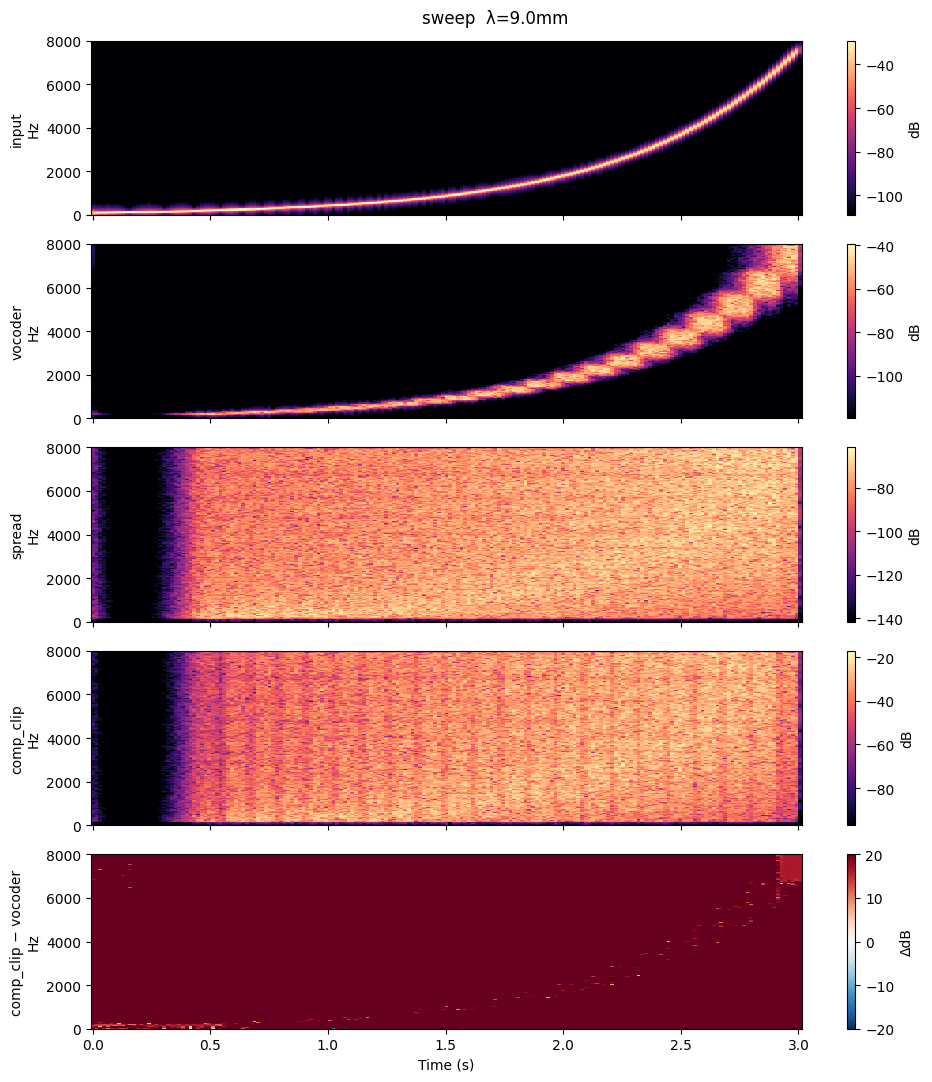

In [7]:
STIM, LAM = "sweep", 9.0
o = OUTS[(STIM, LAM)]

an.plot_spectrograms({k: o[k] for k in ["input", "vocoder", "spread", "comp_clip"]},
                     cfg.sr, diff_pair=("vocoder", "comp_clip"),
                     title=f"{STIM}  λ={LAM}mm");

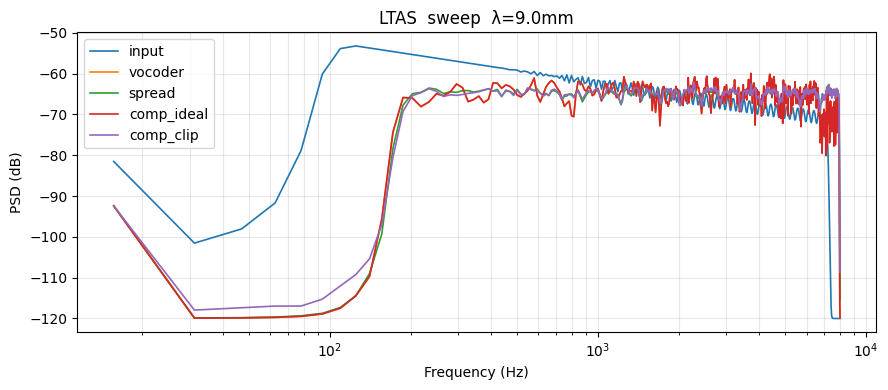

In [8]:
an.plot_ltas({k: o[k] for k in ["input", "vocoder", "spread", "comp_ideal", "comp_clip"]},
            cfg.sr, title=f"LTAS  {STIM}  λ={LAM}mm");

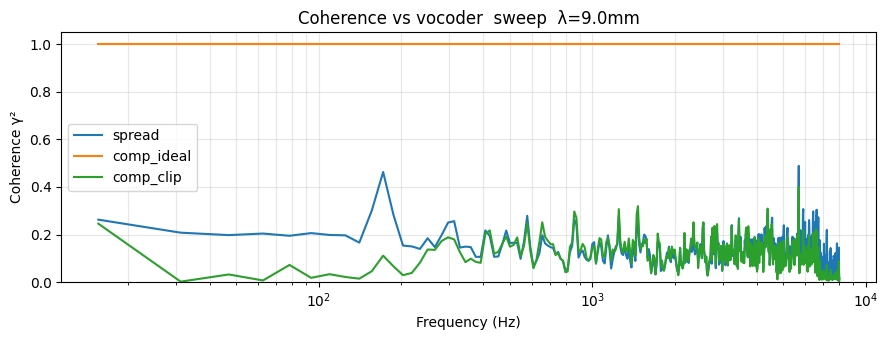

In [9]:
an.plot_coherence(o["vocoder"], {k: o[k] for k in ["spread", "comp_ideal", "comp_clip"]},
                  cfg.sr, title=f"Coherence vs vocoder  {STIM}  λ={LAM}mm");

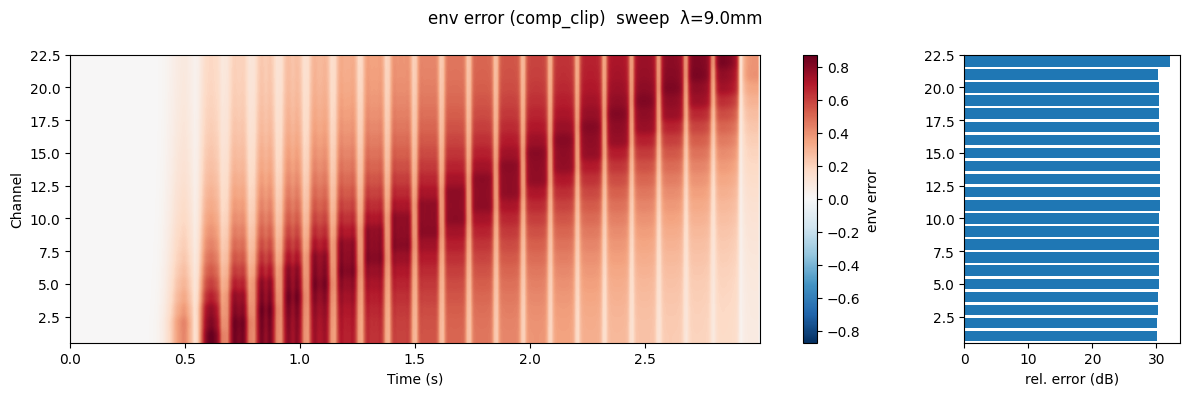

In [10]:
# 包絡誤差ヒートマップ：補償誤差がどのch・どの時刻に出るか
an.plot_env_error(o["env"], o["env_comp_clip"], cfg, title=f"env error (comp_clip)  {STIM}  λ={LAM}mm");

## 6. アブレーション（残留ノイズの原因切り分け）の雛形

1つの要因だけを変えて残差がどう変わるかを見ます。例としてキャリアの乱数シードを振っています。
残差がシードで大きく変わるなら、原因はキャリア（雑音）由来です。他の要因（`n_ch`, `env_cut`, `MODE='tone'`, `EPS`）も同じ形で試せます。

In [11]:
from dataclasses import replace

x = STIMULI["sweep"]()
abl = []
for seed in [0, 1, 2, 3, 4]:
    c = replace(cfg, seed=seed)
    o2 = cs.run_conditions(x, c, lam=9.0, eps=EPS, mode=MODE)
    r = an.compute_metrics(o2["vocoder"], o2["comp_clip"], c, which=["snr", "coherence"])
    r.update(an.env_error(o2["env"], o2["env_comp_clip"]))
    abl.append({"seed": seed, **r})
pd.DataFrame(abl).round(3)

,seed,snr_db,coh_mean,env_rel_err_mean,env_rel_err_max,env_rel_err_db
0,0,-1.236,0.114,1116.579,1612.316,30.448
1,1,-1.255,0.114,1116.579,1612.316,30.448
2,2,-1.256,0.112,1116.579,1612.316,30.448
3,3,-1.298,0.106,1116.579,1612.316,30.448
4,4,-1.242,0.113,1116.579,1612.316,30.448


## メモ：後で直す候補（`cisim.py` 内の `TODO(修正候補○)`）

| # | 内容 | 場所 |
|---|---|---|
| ① | Gを正規化してから逆行列を求める | `make_G_inv()` |
| ② | 事前補償の包絡が負になる（電流は負にできない） | `run_conditions` の `comp_clip` / `neg_ratio` で観察 |
| ③ | 4引数版 `resynthesize` はキャリアを毎回作り直していた | `run_conditions` でキャリアを共通化済み（元ノートとの違い） |
| ④ | ピーク正規化 → レベル比較ならRMS正規化 | `peak_normalize` |
| ⑤ | フィルタの ba形式・lfilter/filtfilt 混在 | `_band_coeffs`, `split_bands` |